# Atmospheric and land initialization benefits for subseasonal 2-m temperature

## Purpose

How much skill does DART initialization of the atmosphere, and of the land, add to subseasonal 2-m temperature forecasts over northern mid-latitude land, as a function of lead week, under the prescribed observed SST of the F20TR hindcasts? A land-atmosphere analogue of the three-panel "initialization contribution" figure: (a) the hypothesis, (b) verification against ERA5, (c) verification against a held-out model member.

## Design

Experiments are referred to by roles, the first digit for the atmosphere and the second for the land (1 = DART-initialized). From each case's namelists (`user_nl_eam` ncdata, `user_nl_elm` finidat), member k of the three configurations used starts from:

| Role | Configuration | Atmosphere, member k | Land, member k |
|---|---|---|---|
| E00 | HYB_BASE | ERA5 + DART perturbation k | DATM-forced land k |
| E10 | DA_ATM | DART analysis k | DATM-forced land k (same file as E00) |
| E11 | DA_COUPLED | DART analysis k (same file as E10) | DART land analysis k |
| E01 | **not run** (a new experiment would be needed) | ERA5 + DART perturbation k (the HYB_BASE atmosphere) | DART land analysis k (the DA_COUPLED land) |

The four roles form a 2 x 2 design: E00 and E01 share the reference atmosphere, E10 and E11 the DART atmosphere; E00 and E10 share the reference land, E01 and E11 the DART land. E01 is the one combination that was not run. DA_LND has the DART land but cannot be E01: all its members start from the same unperturbed ERA5 atmosphere instead of the 20 perturbed HYB_BASE states, so comparing it with E00 or E11 would mix the land change with a change of the atmospheric ensemble. The curves below use only E00, E10 and E11; E01 is needed only for the alternative definitions and the interaction term (see the benefits below).

Benefits (contrasts of skill $S$, `CONTRASTS`):

* atmosphere: $\Delta S_A = S_{10} - S_{00}$, the gain from the DART atmosphere with the reference (DATM-forced) land;
* land: $\Delta S_L = S_{11} - S_{10}$, the gain from the DART land with the DART atmosphere;
* total: $S_{11} - S_{00} = \Delta S_A + \Delta S_L$ exactly.

This is a sequential decomposition along E00 → E10 → E11, so each benefit depends on the order (the land benefit is measured with the DART atmosphere in place). The symmetric definitions centred on full initialization ($S_{11}-S_{01}$, $S_{11}-S_{10}$) and the interaction $S_{11}-S_{10}-S_{01}+S_{00}$ need an E01 run (HYB_BASE atmosphere members with the DART land); set `ROLES["E01"]` and the commented `CONTRASTS` when it exists.

These are **incremental benefits of DART initialization relative to the reference initialization**, not the total atmospheric and land contributions to predictability: the reference atmosphere (ERA5-centred) and land (DATM-forced) already carry information about the target dates. Removing that information would need climatological initial states for one component at a time; CLIM_BASE changes both.

## Inputs

Model: daily-mean TREFHT (mean of the four 6-hour means, `ts/6hourly`) of the matched members (`MEMBER_SET`), lead days 1-56, on the 1-degree grid. Observations: ERA5 daily means (`ERA5/1x1/daily`). Climatologies over `CLIM_YEARS`: observed (monthly means of the ERA5 daily series) and model (the free-running E3SMv3 AMIP runs), both interpolated to the verification days, as in notebook 02 (`util/fcst_init_data.py`).

## Method

1. Daily values of every member on the region's box (cached), and from them two time scales: weekly means (weeks 1-8 = lead days 1-7, ..., 50-56) and centred running means over `SMOOTH_DAYS` lead days at every lead day (the curves of the main figure, as in Richter et al. 2024).
2. Anomalies. Observed: ERA5 minus the observed climatology. Forecast: each member minus the observed (`"none"`) or the AMIP (`"amip"`) climatology (`BIASES`, as in notebook 02).
3. Skill: pattern ACC (centred, cos-lat weighted) over `REGION` of the ensemble mean, for each start and week (or lead day), averaged over the starts (`util/init_benefit.py`). With one year and 4 starts per season, 5 days apart, the gridpoint ACC across starts is too noisy to lead with; it is computed and saved as a secondary diagnostic (maps, weeks 3-4).
4. Uncertainty: a paired bootstrap (`N_BOOT`) resampling the starts within each season and the member indices jointly, with the same draw for every experiment; 2.5-97.5 % intervals.
5. Panel (c): each member k of E11 in turn is the truth; member index k is dropped from every ensemble (in E10 it shares the atmospheric initial state with the truth); forecasts and truth both use the AMIP climatology; skill is averaged over k. This is model-based potential predictability conditional on the prescribed SST, not an upper bound, and it can be inflated by an under-dispersive ensemble.

The main figure follows Richter et al. (2024, Fig. 1): curves at every lead day with the area down to zero shaded and the weeks-2-4 window (`WINDOW_WEEKS`) in grey; the weekly figure carries the bootstrap intervals. The vertical axis is ΔACC: like Richter's contributions (skill differences against runs with one component set to climatology), these are skill differences, here against the reference initialization. Panel (a) is a schematic of the hypothesis (atmospheric benefit early, land benefit relatively more important later); it is drawn, not fitted, and the results decide whether a crossover occurs.

## Limitations

One year, 8 starts (4 per season) that overlap in their verification periods: the intervals are wide and the starts are not independent samples. The benefits are conditional on the reference states (see Design). ERA5 verifies the forecasts and also centres the E00 atmosphere, which favours E00 in week 1. See `METHODS.md` for the data and sampling choices common to the `hind_lead_eval` notebooks.

## Outputs

`data/hind_lead_eval/init_benefit/`: `daily_<CONFIG>_<SEASON>_<VAR>.nc` (daily member values), `daily_ref_<SEASON>_<VAR>.nc` (observations and climatologies), `init_benefit_curves.csv` (skill and contrast curves with intervals, per time scale, bias treatment, panel and season set), `init_benefit_maps_<BIAS>_<SET>.nc` (gridpoint ACC contrasts); figures in `figure/hind_lead_eval/init_benefit/`: `init_benefit_<BIAS>_<SET>.png` (the three-panel figure, daily curves), `init_benefit_weekly_<BIAS>_<SET>.png` (weekly, with intervals), `init_skill_<BIAS>_<SET>.png` (absolute weekly skill), `init_benefit_map_<BIAS>_<SET>.png` (weeks 3-4 gridpoint contrasts).


## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths, experiment roles, contrasts and options. Edit this cell for normal changes; it holds plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction, ELM layer thicknesses
AMIP_ROOT = OBSERVATION_ROOT / "E3SMv3"                        # free-running E3SMv3 DECK AMIP runs
WORKFLOW_NAME = "hind_lead_eval"

# Experiment roles (atmosphere, land; 1 = DART-initialized) and the contrasts plotted
ROLES = {"E00": "HYB_BASE", "E10": "DA_ATM", "E11": "DA_COUPLED", "E01": None}  # E01 not run yet
CONTRASTS = {                       # name: (roles added, roles subtracted)
    "atmosphere": (("E10",), ("E00",)),
    "land": (("E11",), ("E10",)),
    "total": (("E11",), ("E00",)),
}
# With an E01 run (HYB_BASE atmosphere members + DART land), the full-initialization-centred set:
# CONTRASTS = {"atmosphere": (("E11",), ("E01",)), "land": (("E11",), ("E10",)),
#              "interaction": (("E11", "E00"), ("E10", "E01")), "total": (("E11",), ("E00",))}
MEMBER_SET = "matched"     # "matched": the member indices all roles share (same initial files member by member)
MAX_MEMBERS = None         # e.g. 3 for a quick test
REQUIRE_ALL_MEMBERS = True # use a season only when every role's members are post-processed

VARIABLE = "TREFHT"
REGION = dict(name="NH_MIDLAT_LAND", lat=(30.0, 60.0), lon=(0.0, 360.0), mask="land")
SEASONS = ("DJF", "JJA")
MAX_LEAD = 56              # lead days (8 weeks)
CLIM_YEARS = (2001, 2014)  # as notebook 02
AMIP_CASES = ("v3.LR.amip_0101", "v3.LR.amip_0151")
BIASES = ("amip", "none")  # forecast anomaly vs the AMIP (model bias removed) or the observed climatology
MODEL_TRUTH_ROLE = "E11"   # panel (c): held-out members of this role are the truth
N_BOOT = 1000
SEED = 42
SMOOTH_DAYS = 7            # running mean over lead days for the daily curves of the main figure
WINDOW_WEEKS = (2, 4)      # shaded subseasonal window
MAP_WEEKS = (3, 4)         # weeks averaged in the gridpoint-contrast maps

FORCE_COMPUTE = False
SHOW = True
FIGURE_DPI = 200


## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import CONFIGS, STYLE_MAP, check_configs, init_dates, readiness
from configs.output_paths import workflow_output_dirs
from util.init_benefit import member_set, role_configs

roles = role_configs(ROLES)
check_configs(list(roles.values()))
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, "init_benefit", output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(data_root=INPUT_DATA_ROOT, land_support_dir=LAND_SUPPORT_DIR)
members = member_set(ROLES, MEMBER_SET)
members = members if MAX_MEMBERS is None else members[:MAX_MEMBERS]
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")
print(f"[MEMBERS] {len(members)} ({MEMBER_SET}): {', '.join(members)}")
display(pd.DataFrame([dict(role=r, config=c, atmosphere=CONFIGS[c][0], land=CONFIGS[c][1]) for r, c in roles.items()]))


def save(fig, name):
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/init_benefit
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit
[MEMBERS] 11 (matched): EN01, EN03, EN04, EN07, EN08, EN09, EN10, EN14, EN17, EN18, EN20


,role,config,atmosphere,land
0,E00,HYB_BASE,ERA5+DART pert.,DATM-forced
1,E10,DA_ATM,DART,DATM-forced
2,E11,DA_COUPLED,DART,DART


## 4. Read input

Seasons in which every role's members are post-processed.

In [4]:
status = readiness(list(roles.values()), SEASONS, streams=(("atm", "6hourly"),), data_root=INPUT_DATA_ROOT)
summary = status.groupby(["config", "season"]).agg(ready=("ready", "sum"), members=("members", "sum"))
display(summary.unstack("season"))
ready = {(c, s) for (c, s), row in summary.iterrows() if row.ready >= (row.members if REQUIRE_ALL_MEMBERS else 1)}
seasons = [s for s in SEASONS if all((c, s) in ready for c in roles.values())]
print(f"[SEASONS] usable (every role ready): {seasons or 'none'}")
if not seasons:
    raise RuntimeError("No season with every role post-processed")

ready     members    
season       DJF JJA     DJF JJA
config                          
DA_ATM        80  28      80  80
DA_COUPLED    80  28      80  80
HYB_BASE      80  80      80  80

[SEASONS] usable (every role ready): ['DJF']


## 5. Derive and save

Daily values of every matched member, the daily observations and both climatologies on the region's box (cached; reused unless `FORCE_COMPUTE`).

In [5]:
from util.init_benefit import daily_members, daily_references

years = list(range(CLIM_YEARS[0], CLIM_YEARS[1] + 1))
daily, refs = {}, {}
for s in seasons:
    refs[s] = daily_references(VARIABLE, s, years, REGION, max_lead=MAX_LEAD, observation_root=OBSERVATION_ROOT,
                               amip_root=AMIP_ROOT, amip_cases=AMIP_CASES, land_support_dir=LAND_SUPPORT_DIR,
                               cache=data_dir / f"daily_ref_{s}_{VARIABLE}.nc", force=FORCE_COMPUTE)
    for r, c in roles.items():
        daily[r, s] = daily_members(c, s, VARIABLE, members, REGION, max_lead=MAX_LEAD,
                                    cache=data_dir / f"daily_{c}_{s}_{VARIABLE}.nc", force=FORCE_COMPUTE, **ROOTS)
        print(f"[DAILY] {r} {c} {s}: {dict(daily[r, s].sizes)}")
print(f"[CLIM] observed: {refs[seasons[0]].attrs['clim_obs']}\n[CLIM] model: {refs[seasons[0]].attrs['clim_amip']}")

Warning 3: Cannot find header.dxf (GDAL_DATA is not defined)
ERROR 1: PROJ: proj_create_from_database: Cannot find proj.db


[DAILY] E00 HYB_BASE DJF: {'init': 4, 'member': 11, 'lead': 56, 'lat': 30, 'lon': 360}


[DAILY] E10 DA_ATM DJF: {'init': 4, 'member': 11, 'lead': 56, 'lat': 30, 'lon': 360}
[DAILY] E11 DA_COUPLED DJF: {'init': 4, 'member': 11, 'lead': 56, 'lat': 30, 'lon': 360}
[CLIM] observed: ERA5 1x1 daily: monthly means of the daily series
[CLIM] model: E3SMv3 AMIP monthly (v3.LR.amip_0101, v3.LR.amip_0151; cmip_ts (time bounds))


## 6. Scores

On weekly means and on daily running means: panel (b) per bias treatment and season set, panel (c), the curve table, and (weekly) the gridpoint-contrast maps.

In [6]:
from util.fcst_init_data import region_masks
from util.init_benefit import (era5_benefits, lead_in_weeks, model_member_benefits, region_weights, results_table,
                               running_leads, to_weeks)

d0 = refs[seasons[0]]
mask = region_masks([REGION], d0.lat.values, d0.lon.values, land_support_dir=LAND_SUPPORT_DIR).isel(region=0)
w = region_weights(mask)
leads = d0.lead.values
weeks = to_weeks(d0.obs).week.values
x_weeks = lead_in_weeks(leads)
sets = {**({s: [s] for s in seasons} if len(seasons) > 1 else {}), "ALL": seasons}
SCALES = {"weekly": ("week", weeks), "daily": ("lead", leads)}


def prepare(da, scale):
    """Weekly means or ``SMOOTH_DAYS`` running means of an anomaly field, dimensions in a fixed order."""
    out = to_weeks(da) if scale == "weekly" else running_leads(da, SMOOTH_DAYS)
    dims = [d for d in ("init", "member", SCALES[scale][0], "lat", "lon") if d in out.dims]
    return out.transpose(*dims).values


def stack(set_seasons, scale, forecast_clim):
    """Forecast anomalies per role, observed anomalies, and the season of each start."""
    fa = {r: np.concatenate([prepare(daily[r, s] - refs[s][forecast_clim], scale) for s in set_seasons]) for r in roles}
    oa = np.concatenate([prepare(refs[s].obs - refs[s].clim_obs, scale) for s in set_seasons])
    labels = [s for s in set_seasons for _ in range(refs[s].sizes["init"])]
    return fa, oa, labels


results, tables, maps = {}, [], {}
for scale, (axis, coords) in SCALES.items():
    for name, set_seasons in sets.items():
        for b in BIASES:
            fa, oa, labels = stack(set_seasons, scale, "clim_amip" if b == "amip" else "clim_obs")
            res = results[scale, "b", b, name] = era5_benefits(fa, oa, w, CONTRASTS, labels, n_boot=N_BOOT, seed=SEED)
            tables.append(results_table(res, coords, "ERA5", name, axis).assign(bias=b, scale=scale))
            if scale == "weekly":
                maps[b, name] = xr.Dataset({k: (("week", "lat", "lon"), v) for k, v in res["map_contrasts"].items()},
                                           coords={"week": weeks, "lat": d0.lat, "lon": d0.lon}).where(mask)
                maps[b, name].attrs.update(n_starts=len(labels), note="gridpoint ACC across starts; few starts, noisy")
                maps[b, name].to_netcdf(data_dir / f"init_benefit_maps_{b}_{name}.nc")
        if MODEL_TRUTH_ROLE in roles:
            fa, _, labels = stack(set_seasons, scale, "clim_amip")
            res = results[scale, "c", name] = model_member_benefits(fa, MODEL_TRUTH_ROLE, w, CONTRASTS, labels,
                                                                    n_boot=N_BOOT, seed=SEED)
            tables.append(results_table(res, coords, "model member", name, axis).assign(bias="amip", scale=scale))
table = pd.concat(tables, ignore_index=True)
table.to_csv(data_dir / "init_benefit_curves.csv", index=False)
print(f"[WRITE] {data_dir / 'init_benefit_curves.csv'}")
display(table[(table.kind == "contrast") & (table.set == "ALL") & (table.scale == "weekly")]
        .pivot_table(index=["panel", "bias", "name"], columns="step", values="value", sort=False).round(3))

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/init_benefit/init_benefit_curves.csv


step                              1      2      3      4      5      6      7  \
panel        bias name                                                          
ERA5         amip atmosphere  0.162  0.035  0.022  0.321  0.443  0.600  0.351   
                  land        0.017  0.028  0.039 -0.050 -0.096 -0.305 -0.038   
                  total       0.179  0.063  0.061  0.271  0.347  0.295  0.313   
             none atmosphere  0.136  0.046  0.008  0.265  0.380  0.527  0.313   
                  land       -0.013  0.015  0.015 -0.032 -0.067 -0.231 -0.031   
                  total       0.123  0.061  0.024  0.233  0.313  0.295  0.281   
model member amip atmosphere  0.273  0.404  0.204  0.126  0.043  0.031  0.064   
                  land        0.012  0.008 -0.026  0.000  0.011  0.010 -0.007   
                  total       0.285  0.411  0.178  0.126  0.054  0.041  0.057   

step                              8  
panel        bias name               
ERA5         amip atmosphere  0.156  
                  land        0.124  
                  total       0.280  
             none atmosphere  0.145  
                  land        0.060  
                  total       0.205  
model member amip atmosphere  0.100  
                  land       -0.027  
                  total       0.072

## 7. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_benefit_amip_ALL.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_benefit_weekly_amip_ALL.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_skill_amip_ALL.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_benefit_map_amip_ALL.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_benefit_none_ALL.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_benefit_weekly_none_ALL.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_skill_none_ALL.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_benefit_map_none_ALL.png


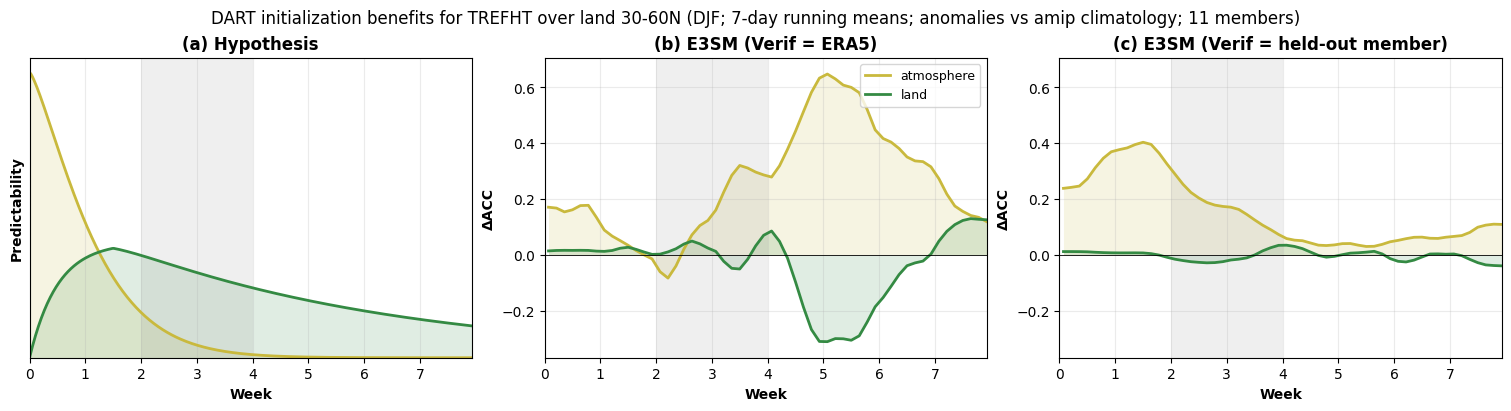

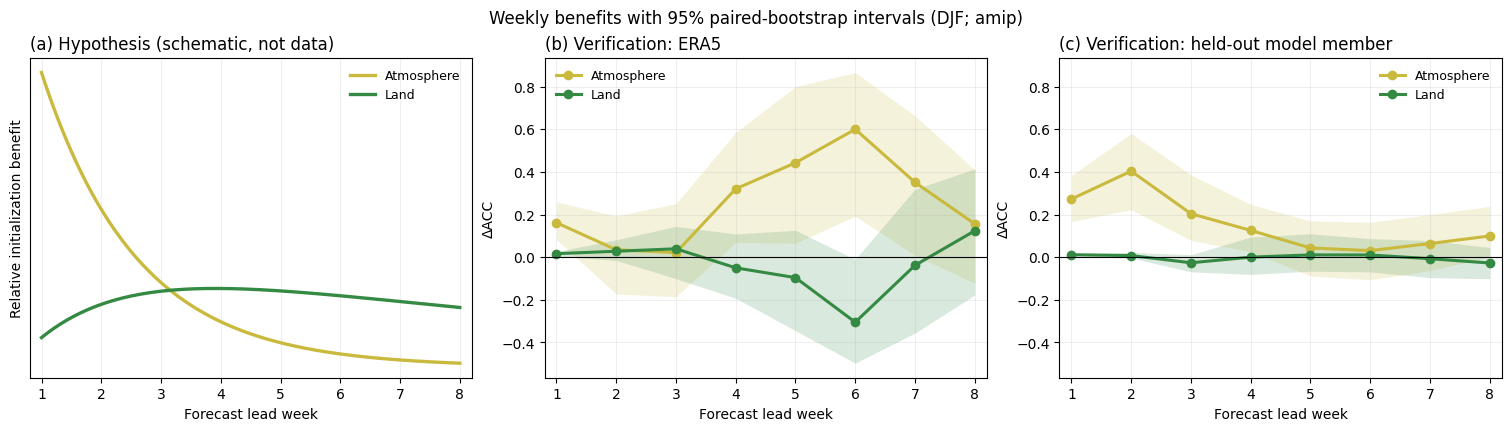

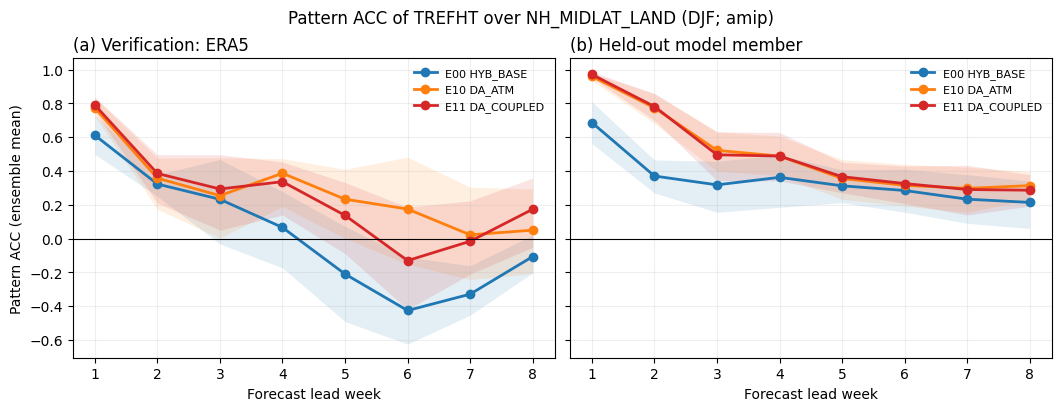

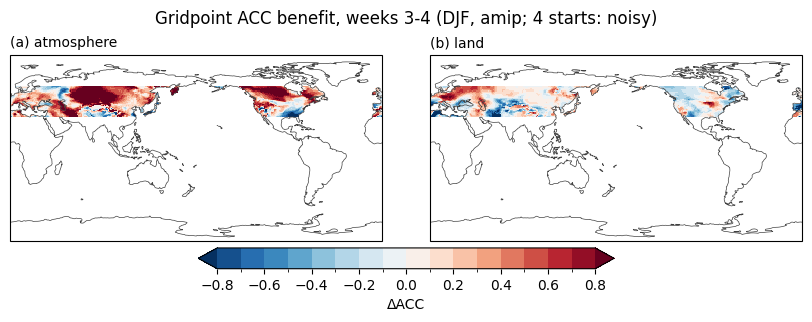

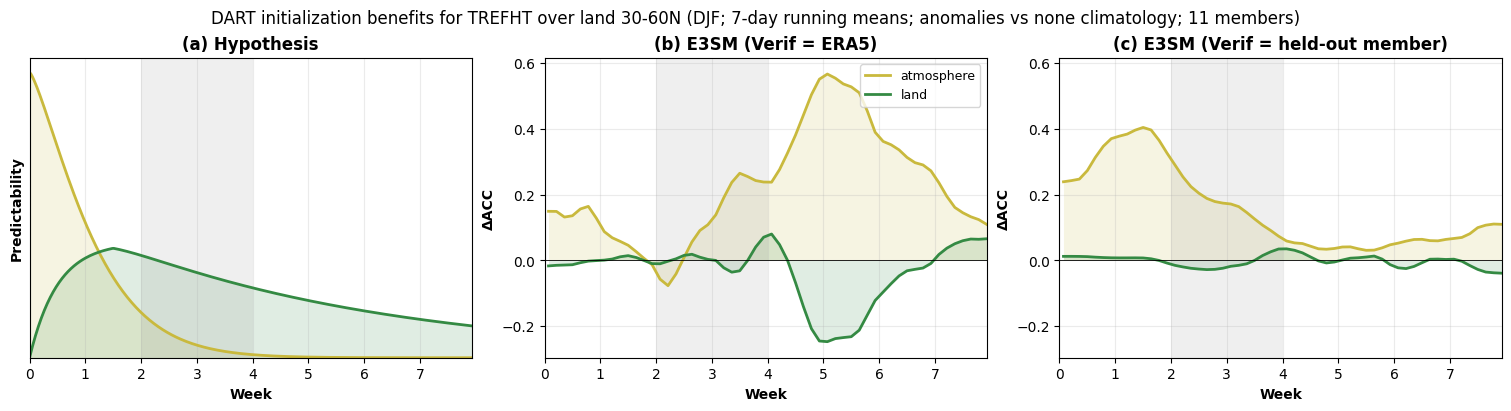

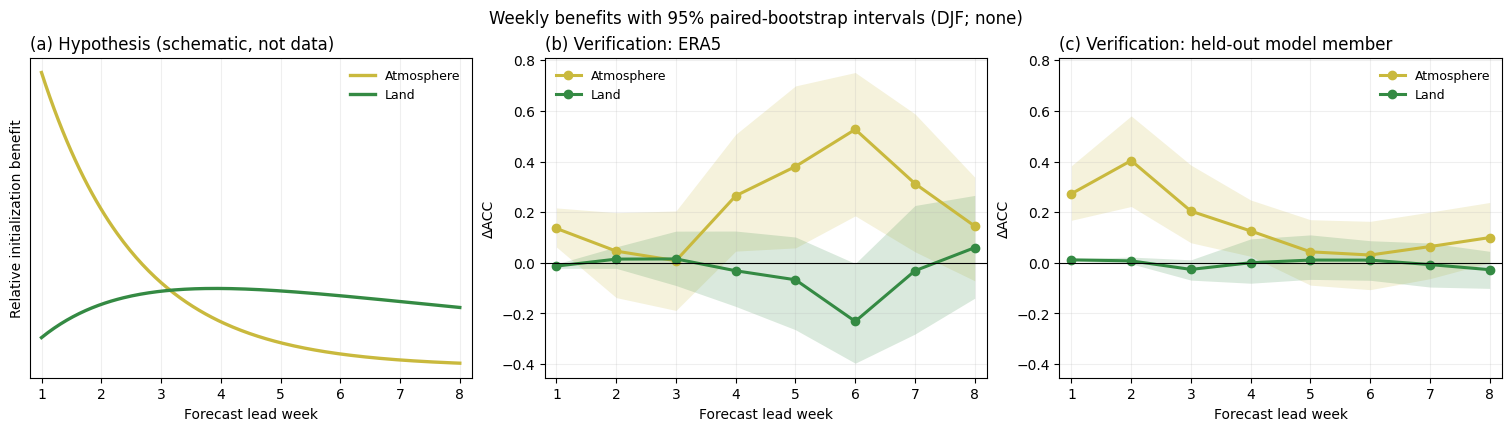

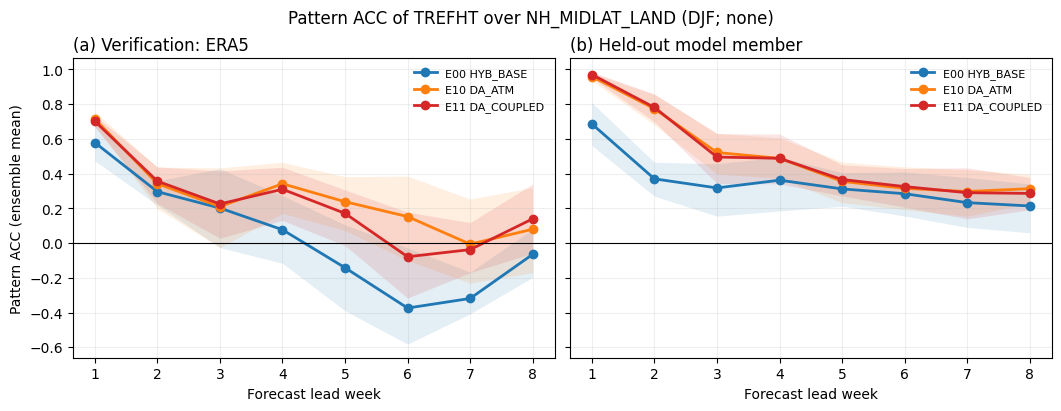

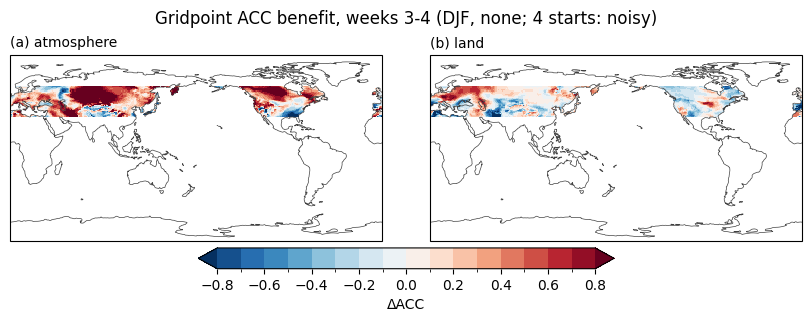

In [7]:
from util.fcst_init_plotting import plot_config_week_maps
from util.init_benefit import plot_benefit_figure, plot_paper_figure, plot_skill_curves, week_index

names = [n for n in ("atmosphere", "land", "interaction") if n in CONTRASTS]
for name, set_seasons in sets.items():
    span = "+".join(set_seasons)
    for b in BIASES:
        pb, pc = results["daily", "b", b, name], results.get(("daily", "c", name))
        save(plot_paper_figure(x_weeks, pb, pc, names=names, window=WINDOW_WEEKS,
                               title=f"DART initialization benefits for {VARIABLE} over land {REGION['lat'][0]:g}-"
                                     f"{REGION['lat'][1]:g}N ({span}; {SMOOTH_DAYS}-day running means; anomalies vs {b} "
                                     f"climatology; {len(members)} members)"),
             f"init_benefit_{b}_{name}.png")
        pb, pc = results["weekly", "b", b, name], results.get(("weekly", "c", name))
        save(plot_benefit_figure(weeks, pb, pc, names=names,
                                 title=f"Weekly benefits with 95% paired-bootstrap intervals ({span}; {b})"),
             f"init_benefit_weekly_{b}_{name}.png")
        save(plot_skill_curves(weeks, pb, pc, roles, STYLE_MAP,
                               title=f"Pattern ACC of {VARIABLE} over {REGION['name']} ({span}; {b})"),
             f"init_skill_{b}_{name}.png")
        idx = week_index(weeks, MAP_WEEKS)
        m = maps[b, name].isel(week=idx).mean("week").expand_dims(week=[MAP_WEEKS[0]])
        save(plot_config_week_maps({k: m[k] for k in names if k in m}, week=MAP_WEEKS[0],
                                   title=f"Gridpoint ACC benefit, weeks {MAP_WEEKS[0]}-{MAP_WEEKS[-1]} ({span}, {b}; "
                                         f"{maps[b, name].attrs['n_starts']} starts: noisy)",
                                   levels=np.linspace(-0.8, 0.8, 17), label="ΔACC"),
             f"init_benefit_map_{b}_{name}.png")